In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("atharvaingle/crop-recommendation-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'crop-recommendation-dataset' dataset.
Path to dataset files: /kaggle/input/crop-recommendation-dataset


In [ ]:

# Step 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [ ]:
import os

# Step 2: Load Dataset from the kagglehub download path
csv_path = os.path.join(path, 'Crop_recommendation.csv')

df = pd.read_csv(csv_path)

# Display first 5 rows
display(df.head())

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [ ]:
# Step 3: Check Dataset Information

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns)
print("\nDataset Information:")
df.info()

Dataset Shape: (2200, 8)

Column Names:
Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [ ]:

# Check missing values in each column
df.isnull().sum()

,0
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0


In [ ]:

# Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [ ]:

# Remove duplicate rows
df = df.drop_duplicates()
print("Dataset Shape After Cleaning:", df.shape)

Dataset Shape After Cleaning: (2200, 8)


In [ ]:

# Statistical summary
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [ ]:

# Count each crop
print(df['label'].value_counts())

label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


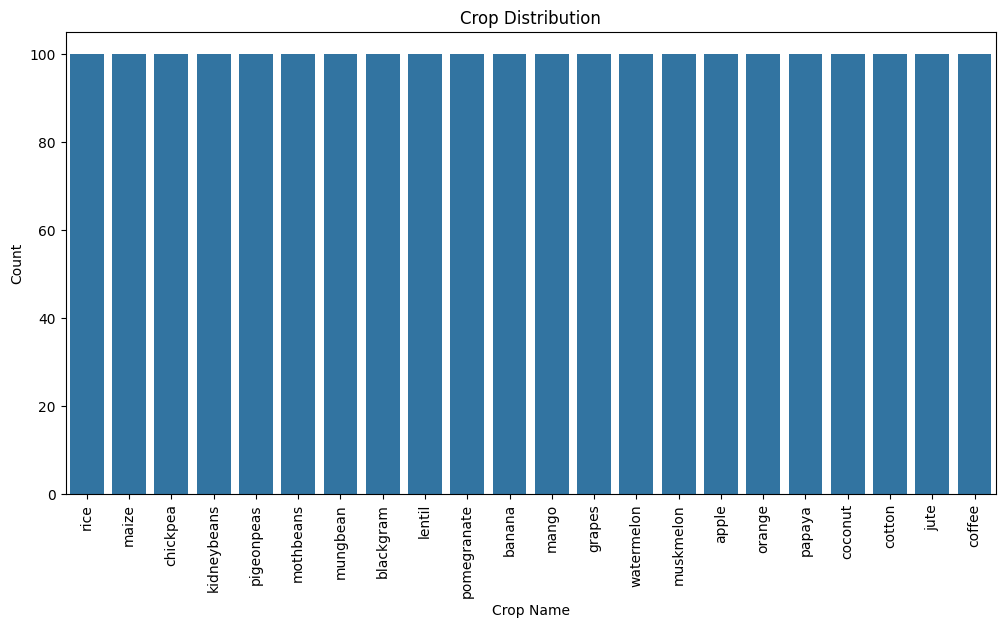

In [ ]:

plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='label')
plt.title('Crop Distribution')
plt.xlabel('Crop Name')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.show()

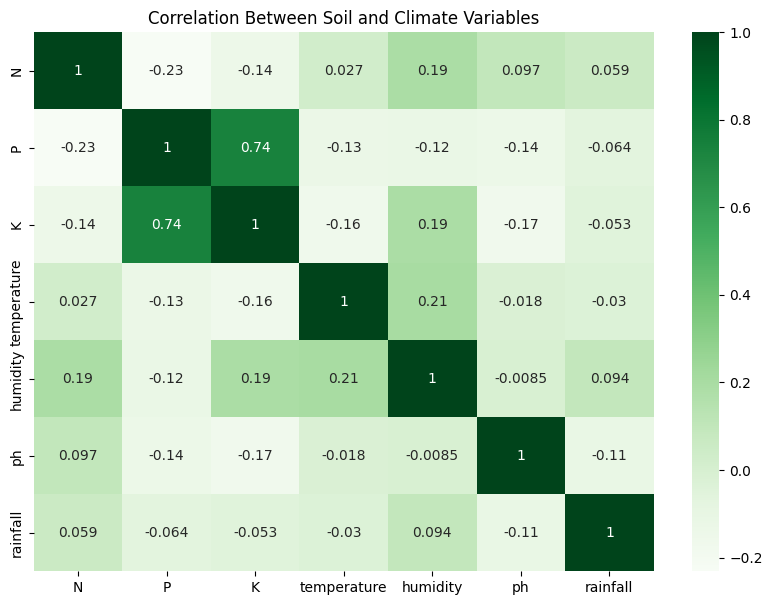

In [ ]:

plt.figure(figsize=(10, 7))
sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='Greens'
)
plt.title('Correlation Between Soil and Climate Variables')
plt.show()


In [ ]:

X = df.drop('label', axis=1)
y = df['label']

print("Input Features:")
print(X.head())

print("\nTarget Output:")
print(y.head())

Input Features:
    N   P   K  temperature   humidity        ph    rainfall
0  90  42  43    20.879744  82.002744  6.502985  202.935536
1  85  58  41    21.770462  80.319644  7.038096  226.655537
2  60  55  44    23.004459  82.320763  7.840207  263.964248
3  74  35  40    26.491096  80.158363  6.980401  242.864034
4  78  42  42    20.130175  81.604873  7.628473  262.717340

Target Output:
0    rice
1    rice
2    rice
3    rice
4    rice
Name: label, dtype: object


In [ ]:

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1760, 7)
Testing Data: (440, 7)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),

    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)
    results[name] = accuracy * 100
    print(name, "Accuracy:", round(accuracy * 100, 2), "%")

Logistic Regression Accuracy: 97.27 %
Decision Tree Accuracy: 97.95 %
Random Forest Accuracy: 99.55 %
KNN Accuracy: 97.95 %


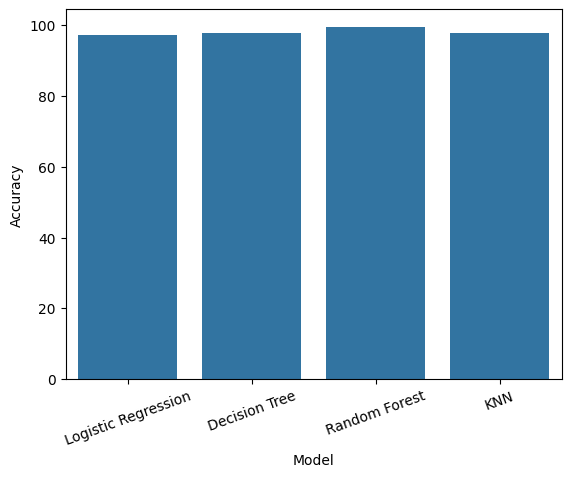

In [ ]:
results_df = pd.DataFrame(
    list(results.items()), columns=['Model', 'Accuracy']
)
sns.barplot(data=results_df, x='Model', y='Accuracy')
plt.xticks(rotation=20)
plt.show()

In [ ]:

from sklearn.metrics import classification_report
best_model_name = max(results, key=results.get)
best_model = models[best_model_name]
predictions = best_model.predict(X_test)
print("Best Model:", best_model_name)
print("\nClassification Report:")
print(classification_report(y_test, predictions))

Best Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.

In [ ]:
print("CROP RECOMMENDATION SYSTEM")
N = float(input("Enter Nitrogen (N): "))
P = float(input("Enter Phosphorus (P): "))
K = float(input("Enter Potassium (K): "))

temperature = float(input("Enter Temperature: "))
humidity = float(input("Enter Humidity: "))
ph = float(input("Enter Soil pH: "))
rainfall = float(input("Enter Rainfall: "))

input_data = pd.DataFrame(
    [[N, P, K, temperature, humidity, ph, rainfall]],
    columns=[
        'N', 'P', 'K',
        'temperature', 'humidity',
        'ph', 'rainfall'
    ]
)
predicted_crop = best_model.predict(input_data)
print("\nRecommended Crop:", predicted_crop[0])

CROP RECOMMENDATION SYSTEM
Enter Nitrogen (N): 16
Enter Phosphorus (P): 13
Enter Potassium (K): 23
Enter Temperature: 6
Enter Humidity: 90
Enter Soil pH: 7.3
Enter Rainfall: 102

Recommended Crop: orange


In [ ]:
import joblib
from google.colab import files

# Select best model
best_model = models[max(results, key=results.get)]

# Save model
joblib.dump(best_model, 'crop_recommendation_model.pkl')

# Download model
files.download('crop_recommendation_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>